<a href="https://colab.research.google.com/github/tjcreate/beginning-python-3ed/blob/master/Code_for_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Code for HW 5: comparing MMSE, Ridge Regression and $\varepsilon$-SVR

The following script contains the functions to generate a correlated random signal and a matrix of buffered windows of that signal. Examples are provided below.

In [ ]:
from scipy import signal
import matplotlib.pyplot as plt
from sklearn.svm import SVR
import numpy as np

def buffer(x, n, hop): #Generated with AI. This returns an array of buffered signal windows
  """
  Args:
    x: Input array.
    n: Length of each buffer.
    hop: Hop size (The overlap is n-hop).

  Returns:
    A 2D array where each row is a buffer.
  """

  if len(x) < n:
    raise ValueError("Input array length must be greater than or equal to the buffer length.")
  num_buffers = (len(x) - n) // hop + 1
  result = np.zeros((num_buffers, n))
  for i in range(num_buffers):
    start = i * hop
    end = start + n
    result[i, :] = x[start:end]
  return result

def signal_gen(sigma, N):
  T=200
  sos = signal.butter(10, 0.2, 'low',output='sos')
  z=np.random.randn(N+T)
  x = signal.sosfilt(sos, z)
  x=x+sigma*np.random.randn(x.shape[0])
  x=x[T:]

  return x

def add_outliers(x,p,a):
  x=x+a*(np.random.rand(x.shape[0])>(1-p))*np.random.randn(x.shape[0])
  return x

In order to illustrate how the buffering works and to explain the code below, please see this example where we generate a silly sequence, we buffeer it and we extract the training regressors.  

In [ ]:
W=5 # This is the window lenght
H=1 # We will use a prediction horizon of one sample ahead
x=np.arange(0,9) # This is the sequence
X=buffer(x,W,1)
y_clean=x[W+H-1:] # We call this "clean" because after extracting it we will contaminate it with some "onservation" noise.
print("Input sequence buffered in a matrix\n", X)
print("Samples to be predicted\n",y_clean)

Input sequence buffered in a matrix
 [[0. 1. 2. 3. 4.]
 [1. 2. 3. 4. 5.]
 [2. 3. 4. 5. 6.]
 [3. 4. 5. 6. 7.]
 [4. 5. 6. 7. 8.]]
Samples to be predicted
 [5 6 7 8]


The print shows the signal buffered in windows of W samples. The first sample in y to be predicted is [5], from [0 1 2 3 4]. Nevertheless, the last sample in y is 8, corresponding to the predictor [3 4 5 6 7]. The last predictor would be used to predict [9], which is not available in y. In general, for horizon H, the last H predictors will be missing. We have to remove them with the next code line.   

In [ ]:
X=X[0:-H] # This removes the last H rows
print("Input sequence buffered in a matrix, with the last H regressors removed\n",X)

Input sequence buffered in a matrix, with the last H regressors removed
 [[0. 1. 2. 3. 4.]
 [1. 2. 3. 4. 5.]
 [2. 3. 4. 5. 6.]
 [3. 4. 5. 6. 7.]]


Next, we generate some training and test signals and define the window length. We plot the training sequence.

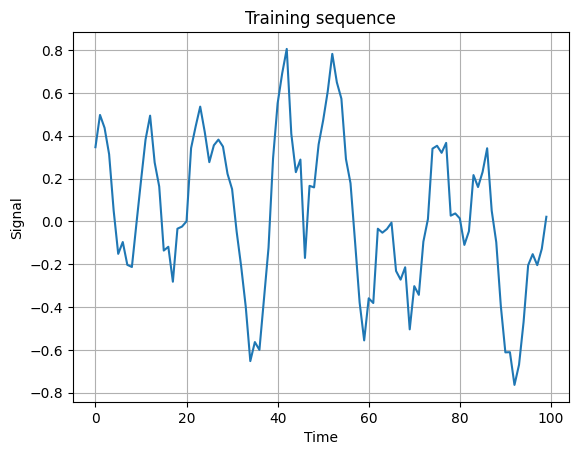

In [ ]:
sigma=np.sqrt(0.01) # STD of the Gaussian noise added to the regressors
W=10
p=0.1 # Outlier probability
a=1   # Outlier STD
xtrain=signal_gen(sigma,100)  # Training sequence
xtest=signal_gen(sigma,100)   # Test sequence
xval=signal_gen(sigma,100)    # Validation sequence

plt.plot(xtrain)
plt.xlabel('Time')
plt.ylabel('Signal')
plt.title('Training sequence')
plt.grid()
plt.show()



Here we create the buffered data and corresponding regressors for training and test and define some variables for the experiments. The regressors are contaminated with outliers. The plots show the clean signal and the outliers

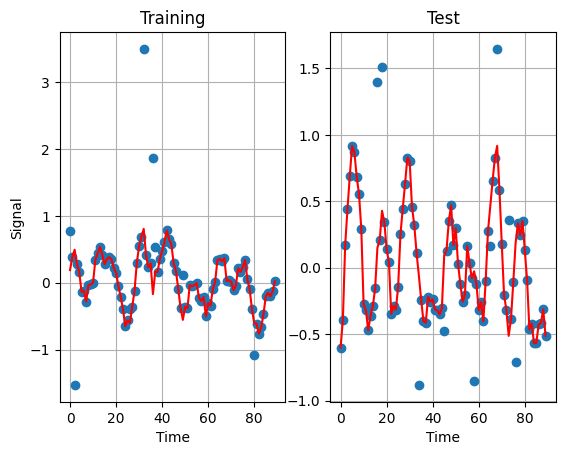

In [ ]:

H=1   # Prediction horizon


Xtrain=buffer(xtrain,W,1)    # Training input data buffered in a matrix
ytrain_clean=xtrain[W+H-1:]  # Training regressors without the outliers. We will use this as groundtruth
ytrain=add_outliers(ytrain_clean,p,a)    # This adds outliers to the regressors
Xtrain=Xtrain[0:-H]          # Remove samples without available regressor.

# Validation and test. We just repeat the code above.
Xval=buffer(xval,W,1)
yval_clean=xval[W+H-1:]
yval=add_outliers(yval_clean,p,a)
Xval=Xval[0:-H]

Xtest=buffer(xtest,W,1)
ytest_clean=xtest[W+H-1:]
ytest=add_outliers(ytest_clean,p,a)
Xtest=Xtest[0:-H]

plt.subplot(1,2,1)
plt.plot(ytrain,'o')
plt.plot(ytrain_clean,'r')
plt.title('Training')
plt.xlabel('Time')
plt.ylabel('Signal')
plt.grid()
plt.subplot(1,2,2)
plt.plot(ytest,'o')
plt.plot(ytest_clean,'r')
plt.title('Test')
plt.xlabel('Time')
plt.grid()
plt.show()

